# Customer-review sentiment: lexicon tools vs a trained classifier (IMDB 50k)
**Question.** For classifying customer feedback, is an off-the-shelf lexicon (VADER, TextBlob) good enough, or is it worth labelling data and training a model? How many labels are needed, and how can uncertain cases be routed to a human?

**Data.** 50,000 movie reviews labelled positive or negative (Maas et al., 2011, *Large Movie Review Dataset*), balanced 50/50. It is a standard stand-in for product reviews, survey comments and support tickets. Companion to project 21, which shows that lexicon tools disagree with each other.

In [1]:
import warnings, pathlib
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110})
IMG = pathlib.Path("images"); IMG.mkdir(exist_ok=True)
import re, time
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer
from textblob import TextBlob
r = pd.read_csv("data/imdb_50k_reviews.csv.gz")
r = r.drop_duplicates("review")
r["text"] = r.review.str.replace(r"<br\s*/?>", " ", regex=True)
r["y"] = (r.sentiment == "positive").astype(int)
print(f"{len(r):,} unique reviews; positive share {r.y.mean():.3f}; median length {r.text.str.split().str.len().median():.0f} words")
tr, te = train_test_split(r, test_size=0.3, stratify=r.y, random_state=0)

49,582 unique reviews; positive share 0.502; median length 172 words


In [2]:
t0 = time.perf_counter(); V = SentimentIntensityAnalyzer()
te = te.assign(vader=[V.polarity_scores(t)["compound"] for t in te.text], textblob=[TextBlob(t).sentiment.polarity for t in te.text])
print(f"lexicon scoring of {len(te):,} reviews: {time.perf_counter() - t0:.0f}s")
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.9, sublinear_tf=True, strip_accents="unicode")
Xtr, Xte = vec.fit_transform(tr.text), vec.transform(te.text)
lr = LogisticRegression(C=4, max_iter=2000).fit(Xtr, tr.y); p_lr = lr.predict_proba(Xte)[:, 1]
svm = LinearSVC(C=0.5).fit(Xtr, tr.y); s_svm = svm.decision_function(Xte)
res = pd.DataFrame({
  "VADER (no training)": {"accuracy": accuracy_score(te.y, te.vader > 0.05), "F1": f1_score(te.y, te.vader > 0.05), "ROC-AUC": roc_auc_score(te.y, te.vader)},
  "TextBlob (no training)": {"accuracy": accuracy_score(te.y, te.textblob > 0.1), "F1": f1_score(te.y, te.textblob > 0.1), "ROC-AUC": roc_auc_score(te.y, te.textblob)},
  "TF-IDF + logistic regression": {"accuracy": accuracy_score(te.y, p_lr > .5), "F1": f1_score(te.y, p_lr > .5), "ROC-AUC": roc_auc_score(te.y, p_lr)},
  "TF-IDF + linear SVM": {"accuracy": accuracy_score(te.y, s_svm > 0), "F1": f1_score(te.y, s_svm > 0), "ROC-AUC": roc_auc_score(te.y, s_svm)}}).T
print(f"{Xtr.shape[1]:,} features from {len(tr):,} training reviews"); res.round(3)

lexicon scoring of 14,875 reviews: 28s


338,581 features from 34,707 training reviews


,accuracy,F1,ROC-AUC
VADER (no training),0.698,0.740,0.787
TextBlob (no training),0.769,0.772,0.848
TF-IDF + logistic regression,0.912,0.912,0.970
TF-IDF + linear SVM,0.914,0.915,0.972


## How many labelled examples are needed?

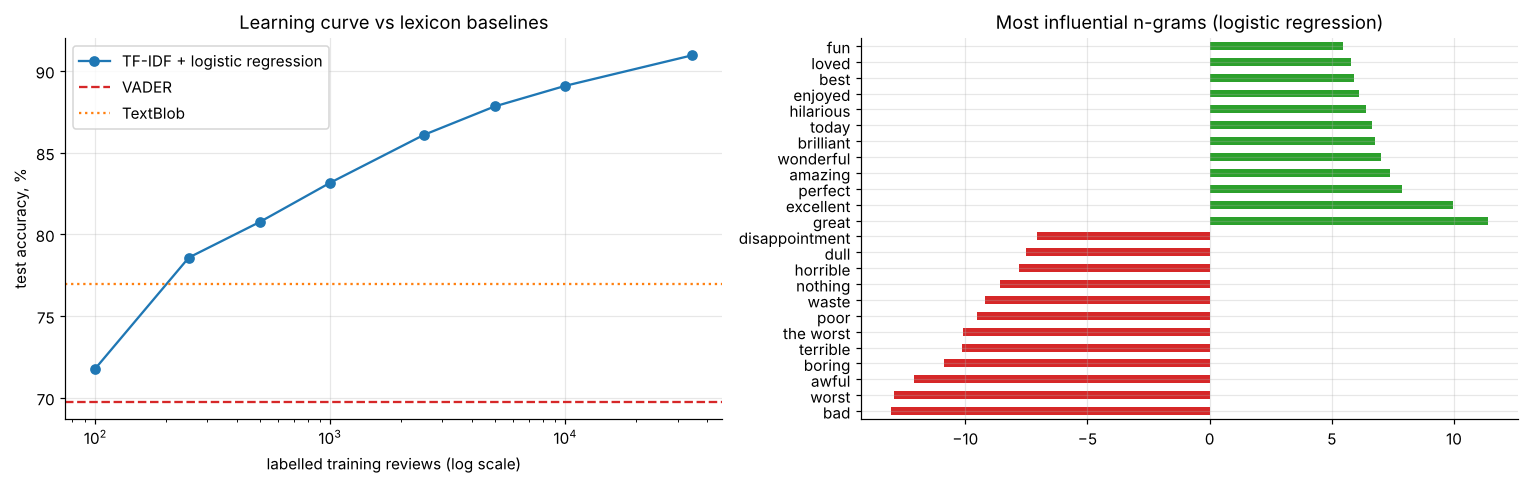

,labels,accuracy
0,100,71.8
1,250,78.6
2,500,80.8
3,1000,83.2
4,2500,86.1
5,5000,87.8
6,10000,89.1
7,34707,91.0


In [3]:
sizes = [100, 250, 500, 1000, 2500, 5000, 10000, len(tr)]
curve = []
for n in sizes:
    sub = tr.sample(n, random_state=1)
    v = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True).fit(sub.text)
    m = LogisticRegression(C=4, max_iter=2000).fit(v.transform(sub.text), sub.y)
    curve.append({"labels": n, "accuracy": accuracy_score(te.y, m.predict(v.transform(te.text)))})
curve = pd.DataFrame(curve)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].semilogx(curve.labels, 100 * curve.accuracy, "o-", label="TF-IDF + logistic regression")
axes[0].axhline(100 * res.loc["VADER (no training)", "accuracy"], c="C3", ls="--", label="VADER")
axes[0].axhline(100 * res.loc["TextBlob (no training)", "accuracy"], c="C1", ls=":", label="TextBlob")
axes[0].set_xlabel("labelled training reviews (log scale)"); axes[0].set_ylabel("test accuracy, %"); axes[0].legend(); axes[0].set_title("Learning curve vs lexicon baselines")
coef = pd.Series(lr.coef_[0], index=vec.get_feature_names_out())
top = pd.concat([coef.nsmallest(12), coef.nlargest(12)])
top.plot.barh(ax=axes[1], color=["C3"] * 12 + ["C2"] * 12, title="Most influential n-grams (logistic regression)")
plt.tight_layout(); plt.savefig(IMG / "learning_curve_features.png", bbox_inches="tight"); plt.show()
curve.assign(accuracy=lambda d: (100 * d.accuracy).round(1))

## Human-in-the-loop routing
Auto-label reviews the model is confident about, and send the rest to a person. Each confidence threshold gives a trade-off between automation rate and accuracy.

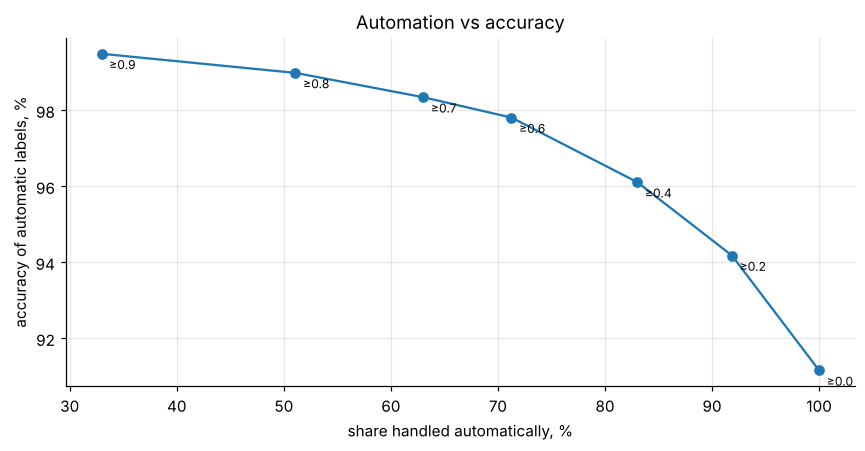

,min confidence,auto-labelled %,accuracy on auto-labelled %
0,0.0,100.0,91.2
1,0.2,91.9,94.2
2,0.4,83.0,96.1
3,0.6,71.3,97.8
4,0.7,63.0,98.3
5,0.8,51.1,99.0
6,0.9,33.0,99.5


In [4]:
conf = np.abs(p_lr - 0.5) * 2
rows = []
for c in [0, .2, .4, .6, .7, .8, .9]:
    auto = conf >= c
    rows.append({"min confidence": c, "auto-labelled %": 100 * auto.mean(), "accuracy on auto-labelled %": 100 * accuracy_score(te.y[auto], p_lr[auto] > .5)})
route = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(route["auto-labelled %"], route["accuracy on auto-labelled %"], "o-")
for r_ in route.itertuples(): ax.annotate(f"≥{r_[1]:.1f}", (r_[2], r_[3]), xytext=(5, -10), textcoords="offset points", fontsize=8)
ax.set_xlabel("share handled automatically, %"); ax.set_ylabel("accuracy of automatic labels, %"); ax.set_title("Automation vs accuracy")
plt.tight_layout(); plt.savefig(IMG / "routing.png", bbox_inches="tight"); plt.show()
route.round(1)

In [5]:
wrong = te.assign(p=p_lr)[(p_lr > .5) != te.y.astype(bool)]
conf_wrong = wrong[~wrong.text.str.contains(r"erotic|sex|nud", case=False)].assign(c=lambda d: np.abs(d.p - .5)).nlargest(3, "c")
for t, y, p in zip(conf_wrong.text, conf_wrong.y, conf_wrong.p):
    print(f"label={'pos' if y else 'neg'}  P(pos)={p:.2f}  | {t[:220]}...\n")

label=neg  P(pos)=0.99  | This is definitely one of the best Kung fu movies in the history of Cinema. The screenplay is really well done (which is not often the case for this type of movies) and you can see that Chuck (in one of his first role)is...

label=pos  P(pos)=0.01  | I was really excited about seeing this film. I thought finally Australia had made a good film.. but I was wrong.  This was the most pathetic attempt at a slasher film ever. I feel sorry for Molly Ringwald having to come ...

label=pos  P(pos)=0.01  | Like the gentle giants that make up the latter half of this film's title, Michael Oblowitz's latest production has grace, but it's also slow and ponderous. The producer's last outing, "Mosquitoman-3D" had the same proble...



## Findings
* **Training beats lexicons by a wide margin.** On 14,875 held-out reviews, TF-IDF with logistic regression or a linear SVM reaches **91% accuracy** (ROC-AUC 0.97), against 77% for TextBlob and 70% for VADER. VADER, built for short social posts, struggles with long reviews that mix praise and criticism.
* **Labels pay off quickly.** With just 250 labelled reviews the classifier already beats both lexicons (79% vs 77%). With 2,500 it reaches 86%, and beyond about 10,000 the gains flatten (89% to 91%).
* **The model is interpretable:** "worst", "awful", "waste", "bad" and "boring" push towards negative; "great", "excellent", "perfect" and "best" towards positive.
* **Human-in-the-loop is where the business value is.** Auto-labelling only reviews with confidence ≥ 0.6 handles 71% of the volume at **97.8% accuracy**, leaving 29% for people. At ≥ 0.8 it handles half at 99.0%.
* **Many confident "errors" are label noise:** the most confident mistakes include reviews whose text clearly contradicts their rating, which is worth auditing in any real labelled dataset.